In [2]:
# Customer Churn Exploratory Data Analysis
# Task 2

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Set project paths
DATA_PATH = Path("data/cleaned/cleaned_customer_churn.csv")
PLOT_PATH = Path("../outputs/plots")

PLOT_PATH.mkdir(parents=True, exist_ok=True)

# Set visualization style
sns.set_theme(style="whitegrid", palette="Set2")

# Load cleaned dataset
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nFirst five records:")
display(df.head())

Dataset loaded successfully!
Dataset shape: (7043, 21)

First five records:


,customer_id,gender,senior_citizen,partner,dependents,tenure,phone_service,multiple_lines,internet_service,online_security,...,device_protection,tech_support,streaming_tv,streaming_movies,contract,paperless_billing,payment_method,monthly_charge,total_charge,churn_flag
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


In [3]:
# 1. Dataset information
print("DATASET INFORMATION")
print("=" * 50)

df.info()

# 2. Dataset dimensions
print("\nDATASET DIMENSIONS")
print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])

# 3. Summary statistics for numerical columns
print("\nNUMERICAL SUMMARY STATISTICS")
display(df.describe())

# 4. Summary of categorical columns
print("\nCATEGORICAL SUMMARY")
display(df.describe(include="object").T)

# 5. Churn distribution
print("\nCHURN DISTRIBUTION")
print(df["churn_flag"].value_counts())

# 6. Churn percentage
print("\nCHURN PERCENTAGE")
display(
    (df["churn_flag"].value_counts(normalize=True) * 100)
    .rename("Percentage")
    .round(2)
)

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   customer_id        7043 non-null   object 
 1   gender             7043 non-null   object 
 2   senior_citizen     7043 non-null   int64  
 3   partner            7043 non-null   object 
 4   dependents         7043 non-null   object 
 5   tenure             7043 non-null   int64  
 6   phone_service      7043 non-null   object 
 7   multiple_lines     7043 non-null   object 
 8   internet_service   7043 non-null   object 
 9   online_security    7043 non-null   object 
 10  online_backup      7043 non-null   object 
 11  device_protection  7043 non-null   object 
 12  tech_support       7043 non-null   object 
 13  streaming_tv       7043 non-null   object 
 14  streaming_movies   7043 non-null   object 
 15  contract           7043 non-null   object 
 16  pape

,senior_citizen,tenure,monthly_charge,total_charge,churn_flag
count,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304,0.265370
std,0.368612,24.559481,30.090047,2266.794470,0.441561
min,0.000000,0.000000,18.250000,0.000000,0.000000
25%,0.000000,9.000000,35.500000,398.550000,0.000000
50%,0.000000,29.000000,70.350000,1394.550000,0.000000
75%,0.000000,55.000000,89.850000,3786.600000,1.000000
max,1.000000,72.000000,118.750000,8684.800000,1.000000



CATEGORICAL SUMMARY


,count,unique,top,freq
customer_id,7043,7043,3186-AJIEK,1
gender,7043,2,Male,3555
partner,7043,2,No,3641
dependents,7043,2,No,4933
phone_service,7043,2,Yes,6361
multiple_lines,7043,3,No,3390
internet_service,7043,3,Fiber optic,3096
online_security,7043,3,No,3498
online_backup,7043,3,No,3088
device_protection,7043,3,No,3095



CHURN DISTRIBUTION
churn_flag
0    5174
1    1869
Name: count, dtype: int64

CHURN PERCENTAGE


churn_flag
0    73.46
1    26.54
Name: Percentage, dtype: float64

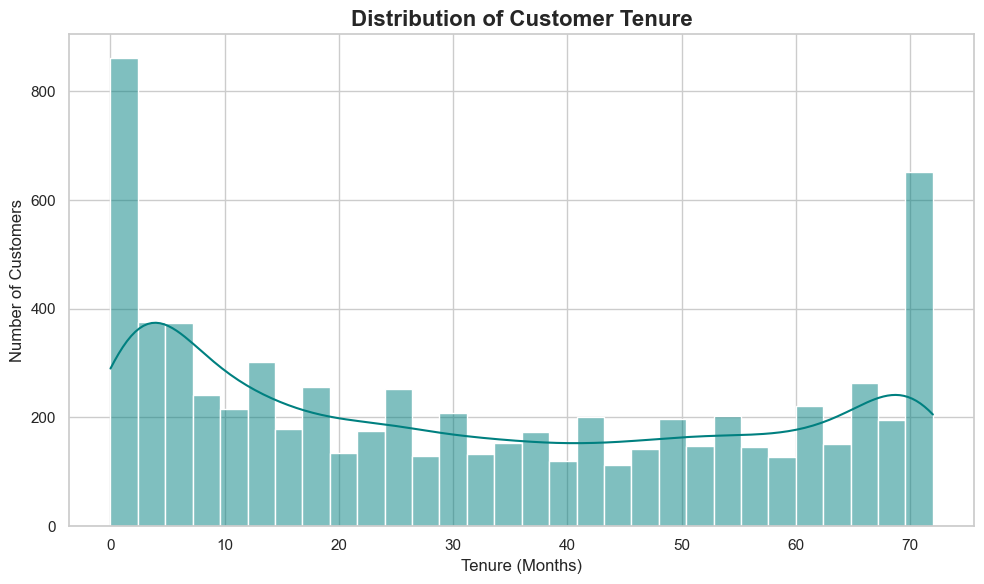

In [4]:
# Visualization 1: Customer Tenure Distribution

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="tenure",
    bins=30,
    kde=True,
    color="teal"
)

plt.title("Distribution of Customer Tenure", fontsize=16, fontweight="bold")
plt.xlabel("Tenure (Months)", fontsize=12)
plt.ylabel("Number of Customers", fontsize=12)

plt.tight_layout()

plt.savefig(
    "outputs/plots/01_customer_tenure_histogram.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

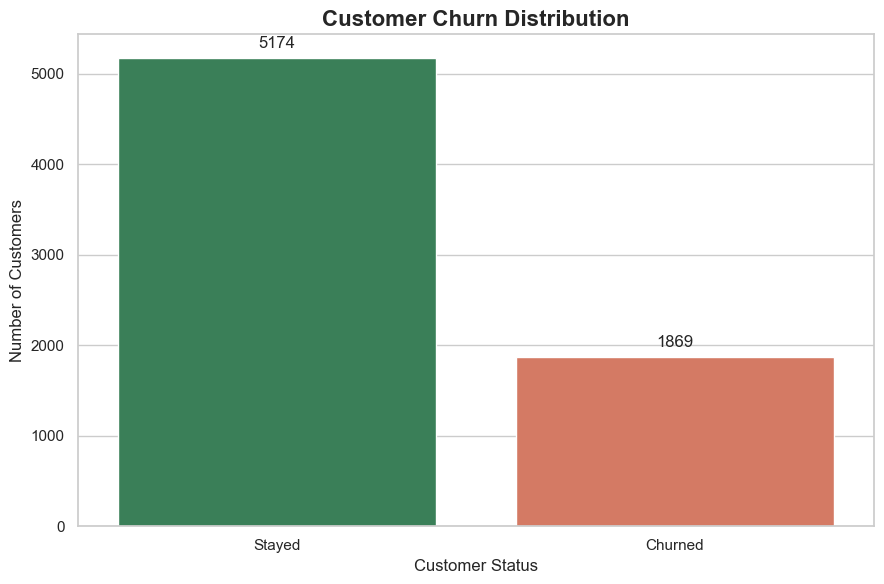

In [5]:
# Visualization 2: Churn Distribution

churn_counts = df["churn_flag"].value_counts().sort_index()

plt.figure(figsize=(9, 6))

ax = sns.barplot(
    x=["Stayed", "Churned"],
    y=churn_counts.values,
    hue=["Stayed", "Churned"],
    palette=["#2E8B57", "#E76F51"],
    legend=False
)

plt.title("Customer Churn Distribution", fontsize=16, fontweight="bold")
plt.xlabel("Customer Status", fontsize=12)
plt.ylabel("Number of Customers", fontsize=12)

# Display values above bars
for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=5)

plt.tight_layout()

plt.savefig(
    "outputs/plots/02_churn_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

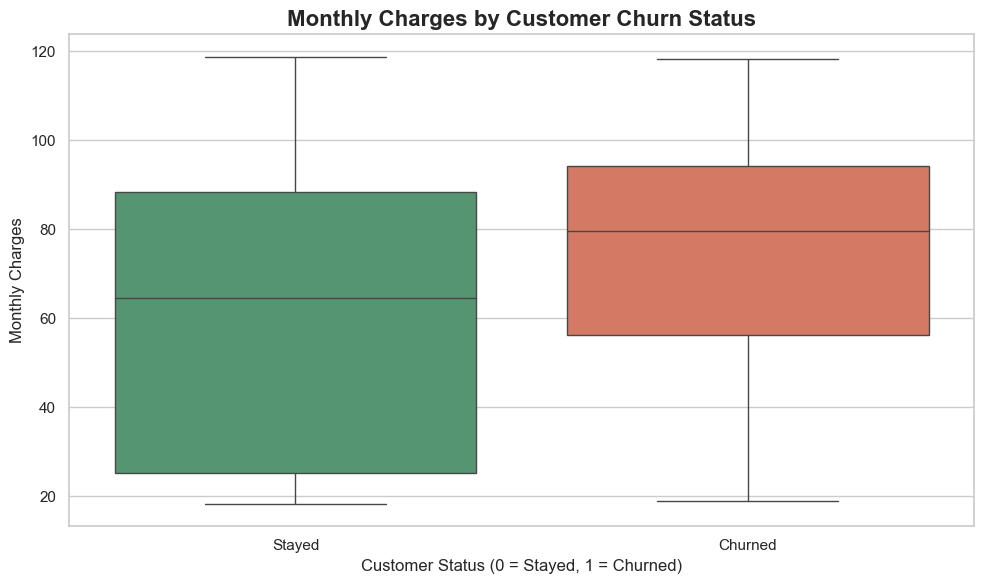

In [6]:
# Visualization 3: Monthly Charges by Churn Status

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="churn_flag",
    y="monthly_charge",
    hue="churn_flag",
    palette=["#4C9F70", "#E76F51"],
    legend=False
)

plt.title("Monthly Charges by Customer Churn Status",
          fontsize=16, fontweight="bold")

plt.xlabel("Customer Status (0 = Stayed, 1 = Churned)")
plt.ylabel("Monthly Charges")

plt.xticks([0, 1], ["Stayed", "Churned"])

plt.tight_layout()

plt.savefig(
    "outputs/plots/03_monthly_charges_boxplot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

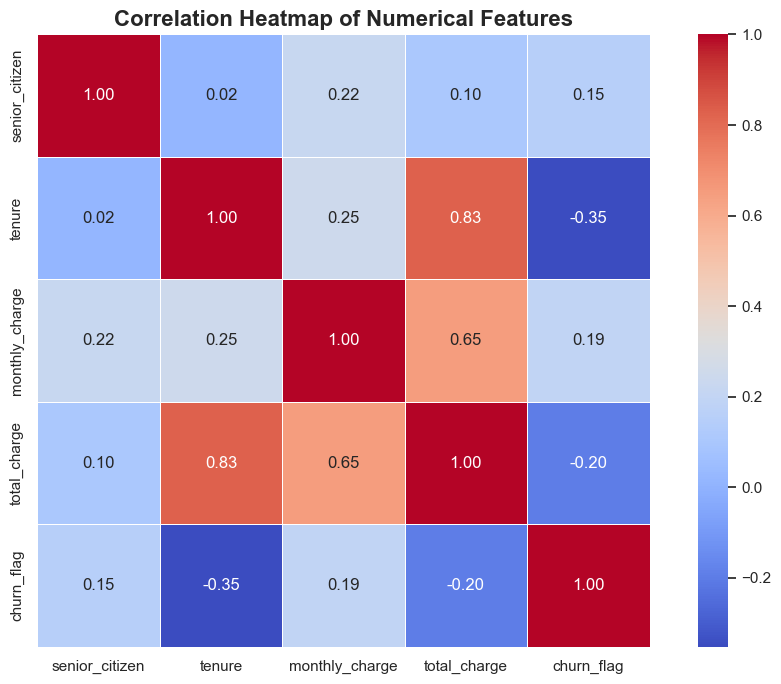

In [7]:
# Visualization 4: Correlation Heatmap

numerical_df = df.select_dtypes(include="number")

correlation_matrix = numerical_df.corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    square=True
)

plt.title("Correlation Heatmap of Numerical Features",
          fontsize=16, fontweight="bold")

plt.tight_layout()

plt.savefig(
    "outputs/plots/04_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

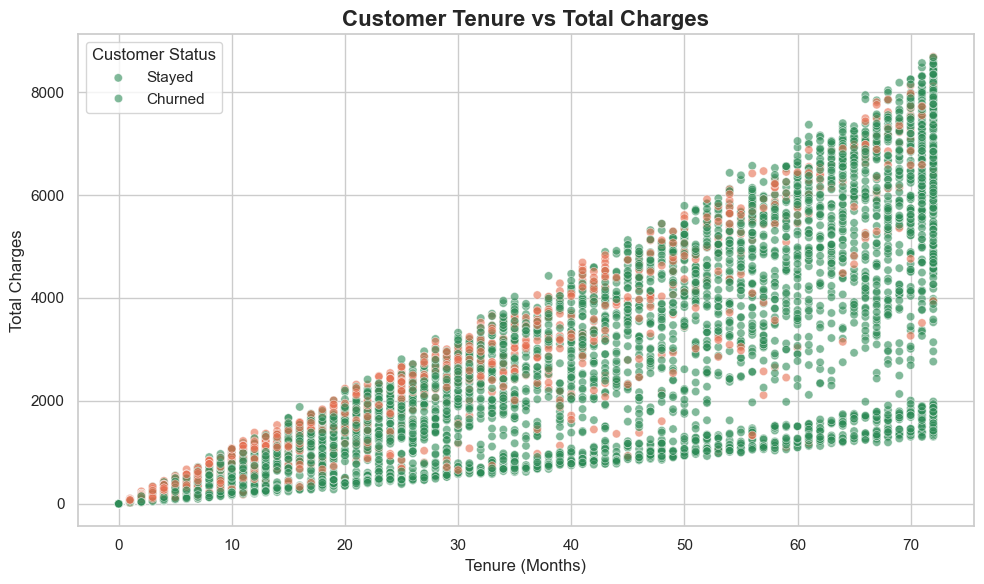

In [8]:
# Visualization 5: Tenure vs Total Charges

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="tenure",
    y="total_charge",
    hue="churn_flag",
    palette={0: "#2E8B57", 1: "#E76F51"},
    alpha=0.6
)

plt.title("Customer Tenure vs Total Charges",
          fontsize=16, fontweight="bold")

plt.xlabel("Tenure (Months)")
plt.ylabel("Total Charges")

plt.legend(
    title="Customer Status",
    labels=["Stayed", "Churned"]
)

plt.tight_layout()

plt.savefig(
    "outputs/plots/05_tenure_vs_total_charges.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [9]:
from pathlib import Path

plot_files = list(Path("outputs/plots").glob("*.png"))

print("Total visualizations:", len(plot_files))

for file in sorted(plot_files):
    print(file.name)

Total visualizations: 5
01_customer_tenure_histogram.png
02_churn_distribution.png
03_monthly_charges_boxplot.png
04_correlation_heatmap.png
05_tenure_vs_total_charges.png


In [10]:
def churn_rate_by(column):
    result = (
        df.groupby(column)["churn_flag"]
        .agg(
            total_customers="count",
            churned_customers="sum",
            churn_rate="mean"
        )
        .reset_index()
    )

    result["churn_rate"] = (result["churn_rate"] * 100).round(2)

    return result.sort_values(
        by="churn_rate",
        ascending=False
    )


# Analyze churn across different categories
columns_to_analyze = [
    "contract",
    "internet_service",
    "payment_method",
    "tech_support",
    "online_security"
]

for column in columns_to_analyze:
    print(f"\nCHURN ANALYSIS BY {column.upper()}")
    display(churn_rate_by(column))


CHURN ANALYSIS BY CONTRACT


,contract,total_customers,churned_customers,churn_rate
0,Month-to-month,3875,1655,42.71
1,One year,1473,166,11.27
2,Two year,1695,48,2.83



CHURN ANALYSIS BY INTERNET_SERVICE


,internet_service,total_customers,churned_customers,churn_rate
1,Fiber optic,3096,1297,41.89
0,DSL,2421,459,18.96
2,No,1526,113,7.40



CHURN ANALYSIS BY PAYMENT_METHOD


,payment_method,total_customers,churned_customers,churn_rate
2,Electronic check,2365,1071,45.29
3,Mailed check,1612,308,19.11
0,Bank transfer (automatic),1544,258,16.71
1,Credit card (automatic),1522,232,15.24



CHURN ANALYSIS BY TECH_SUPPORT


,tech_support,total_customers,churned_customers,churn_rate
0,No,3473,1446,41.64
2,Yes,2044,310,15.17
1,No internet service,1526,113,7.40



CHURN ANALYSIS BY ONLINE_SECURITY


,online_security,total_customers,churned_customers,churn_rate
0,No,3498,1461,41.77
2,Yes,2019,295,14.61
1,No internet service,1526,113,7.40


In [11]:
# Create customer tenure groups
df["tenure_group"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=[
        "0-12 months",
        "13-24 months",
        "25-48 months",
        "49-72 months"
    ]
)

# Calculate churn rate for each tenure group
tenure_churn = (
    df.groupby("tenure_group", observed=False)["churn_flag"]
    .agg(
        total_customers="count",
        churned_customers="sum",
        churn_rate="mean"
    )
    .reset_index()
)

tenure_churn["churn_rate"] = (
    tenure_churn["churn_rate"] * 100
).round(2)

display(tenure_churn)

,tenure_group,total_customers,churned_customers,churn_rate
0,0-12 months,2186,1037,47.44
1,13-24 months,1024,294,28.71
2,25-48 months,1594,325,20.39
3,49-72 months,2239,213,9.51


In [12]:
from pathlib import Path

# Create reports folder if it does not exist
Path("reports").mkdir(parents=True, exist_ok=True)

report = """
# Customer Churn - Exploratory Data Analysis (EDA) Report

## 1. Project Overview

This report presents an exploratory data analysis of the cleaned IBM Telco
Customer Churn dataset. The purpose is to understand customer behavior,
identify patterns associated with churn, and provide insights that may
help improve customer retention.

## 2. Dataset Overview

- Total customers: 7,043
- Total columns: 21
- Missing values: 0
- Duplicate records: 0
- Churned customers: 1,869
- Customers who stayed: 5,174

## 3. Key Statistics

- Overall churn rate: 26.54%
- Customer retention rate: 73.46%
- Average customer tenure: 32.37 months
- Median customer tenure: 29 months
- Average monthly charge: 64.76

## 4. Customer Churn Analysis

### Contract Type

- Month-to-month contracts: 42.71% churn rate.
- One-year contracts: 11.27% churn rate.
- Two-year contracts: 2.83% churn rate.

Month-to-month customers have the highest churn rate among the contract
groups.

### Internet Service

- Fiber optic: 41.89% churn rate.
- DSL: 18.96% churn rate.
- No internet service: 7.40% churn rate.

Fiber optic customers show a higher churn rate than DSL customers.

### Payment Method

- Electronic check: 45.29% churn rate.
- Mailed check: 19.11% churn rate.
- Bank transfer (automatic): 16.71% churn rate.
- Credit card (automatic): 15.24% churn rate.

Electronic check users have the highest churn rate among payment methods.

### Tech Support

- No tech support: 41.64% churn rate.
- Tech support: 15.17% churn rate.
- No internet service: 7.40% churn rate.

Customers without tech support show a higher churn rate.

### Online Security

- No online security: 41.77% churn rate.
- Online security: 14.61% churn rate.
- No internet service: 7.40% churn rate.

Customers without online security show a higher churn rate.

### Customer Tenure

- 0-12 months: 47.44% churn rate.
- 13-24 months: 28.71% churn rate.
- 25-48 months: 20.39% churn rate.
- 49-72 months: 9.51% churn rate.

Customers with shorter tenure show higher churn rates. The first year
appears to be an important period for customer retention.

## 5. Key Business Insights

1. Month-to-month contract customers are more likely to leave than
   customers with longer contracts.
2. Electronic check users have the highest churn rate among payment
   method groups.
3. Fiber optic customers show higher churn than DSL customers.
4. Customers without tech support or online security show higher
   churn rates.
5. New customers, especially those with less than one year of tenure,
   have a higher churn rate.

## 6. Recommendations

1. Improve onboarding and customer engagement during the first year.
2. Consider retention offers for month-to-month customers.
3. Investigate customer satisfaction among fiber optic users.
4. Review the payment experience for electronic check users.
5. Promote the availability and benefits of technical support and
   online security services.

## 7. Visualizations

The following visualizations were created during the analysis:

1. Customer tenure histogram
2. Customer churn distribution
3. Monthly charges by churn status
4. Numerical correlation heatmap
5. Customer tenure versus total charges

All plots are saved in the `outputs/plots/` directory.

## 8. Conclusion

The analysis identifies several customer groups with higher churn rates,
particularly month-to-month customers, electronic check users, and
customers with shorter tenure. These patterns can help the business
identify areas for further investigation and develop customer retention
strategies.

Note: These findings describe associations in the dataset. They do not
establish that any individual feature directly causes customer churn.
The dataset is the IBM Telco Customer Churn dataset and represents
telecommunications customers, not actual boutique transactions.
"""

with open("reports/eda_insights.md", "w", encoding="utf-8") as file:
    file.write(report)

print("EDA insights report saved successfully!")

EDA insights report saved successfully!


In [13]:
from pathlib import Path

report_path = Path("reports/eda_insights.md")

print("Report exists:", report_path.exists())
print("Report location:", report_path)

Report exists: True
Report location: reports\eda_insights.md


In [14]:
from matplotlib.backends.backend_pdf import PdfPages
import matplotlib.pyplot as plt
from pathlib import Path
import textwrap

# Define paths
PLOT_PATH = Path("outputs/plots")
REPORT_PATH = Path("reports/customer_churn_eda_report.pdf")

# Create reports folder if needed
REPORT_PATH.parent.mkdir(parents=True, exist_ok=True)

# Report summary
summary = """
DATASET OVERVIEW

Total customers: 7,043
Total columns: 21
Missing values: 0
Duplicate records: 0

CHURN SUMMARY

Churned customers: 1,869 (26.54%)
Customers retained: 5,174 (73.46%)

AVERAGE CUSTOMER STATISTICS

Average tenure: 32.37 months
Median tenure: 29 months
Average monthly charge: 64.76

KEY FINDINGS

1. Month-to-month customers have a 42.71% churn rate.
2. Fiber optic customers have a 41.89% churn rate.
3. Electronic check users have a 45.29% churn rate.
4. Customers without tech support have a 41.64% churn rate.
5. Customers without online security have a 41.77% churn rate.
6. Customers with 0-12 months tenure have a 47.44% churn rate.
7. Customers with 49-72 months tenure have a 9.51% churn rate.

BUSINESS RECOMMENDATIONS

- Improve onboarding for new customers.
- Consider retention offers for month-to-month customers.
- Investigate customer satisfaction among fiber optic users.
- Review the payment experience for electronic check users.
- Promote technical support and online security services.

CONCLUSION

The analysis identifies customer groups with higher churn rates.
These patterns can help the business investigate customer retention
and improve its services.

IMPORTANT NOTE

These findings show associations, not proof of causation.
The dataset is the IBM Telco Customer Churn dataset and represents
telecommunications customers, not actual boutique transactions.
"""

# Chart files
chart_files = [
    "01_customer_tenure_histogram.png",
    "02_churn_distribution.png",
    "03_monthly_charges_boxplot.png",
    "04_correlation_heatmap.png",
    "05_tenure_vs_total_charges.png"
]

# Check that all charts exist
missing_charts = [
    name for name in chart_files
    if not (PLOT_PATH / name).exists()
]

if missing_charts:
    raise FileNotFoundError(
        f"Missing chart files: {missing_charts}"
    )

# Generate PDF
with PdfPages(REPORT_PATH) as pdf:

    # Page 1: Report overview
    fig = plt.figure(figsize=(8.27, 11.69))
    fig.suptitle(
        "CUSTOMER CHURN\nEXPLORATORY DATA ANALYSIS",
        fontsize=21,
        fontweight="bold",
        y=0.94
    )

    fig.text(
        0.10, 0.85,
        "Internship Project | EDA Report",
        fontsize=13
    )

    fig.text(
        0.10, 0.78,
        summary,
        fontsize=11,
        va="top",
        linespacing=1.6
    )

    pdf.savefig(fig, bbox_inches="tight")
    plt.close(fig)

    # Remaining pages: One chart per page
    for chart_name in chart_files:

        image = plt.imread(PLOT_PATH / chart_name)

        fig, ax = plt.subplots(figsize=(8.27, 11.69))

        ax.imshow(image)
        ax.axis("off")

        title = chart_name.replace(".png", "")
        title = title.replace("_", " ").title()

        fig.suptitle(
            title,
            fontsize=17,
            fontweight="bold",
            y=0.94
        )

        pdf.savefig(fig, bbox_inches="tight")
        plt.close(fig)

print("PDF report generated successfully!")
print("Location:", REPORT_PATH)

PDF report generated successfully!
Location: reports\customer_churn_eda_report.pdf


In [15]:
pdf_path = Path("reports/customer_churn_eda_report.pdf")

print("PDF exists:", pdf_path.exists())

if pdf_path.exists():
    print("PDF size:", round(pdf_path.stat().st_size / 1024, 2), "KB")

PDF exists: True
PDF size: 312.58 KB


In [16]:
from pathlib import Path

required_files = [
    "notebooks/customer_churn_eda.ipynb",
    "reports/eda_insights.md",
    "reports/customer_churn_eda_report.pdf",
    "outputs/plots/01_customer_tenure_histogram.png",
    "outputs/plots/02_churn_distribution.png",
    "outputs/plots/03_monthly_charges_boxplot.png",
    "outputs/plots/04_correlation_heatmap.png",
    "outputs/plots/05_tenure_vs_total_charges.png",
    "README.md",
    "requirements.txt"
]

print("TASK 2 FILE VERIFICATION")
print("-" * 45)

for file in required_files:
    path = Path(file)
    status = "FOUND" if path.exists() else "MISSING"
    print(f"{status}: {file}")

missing = [f for f in required_files if not Path(f).exists()]

print("-" * 45)

if not missing:
    print("All required files are present!")
else:
    print("Files still missing:", missing)

TASK 2 FILE VERIFICATION
---------------------------------------------
MISSING: notebooks/customer_churn_eda.ipynb
FOUND: reports/eda_insights.md
FOUND: reports/customer_churn_eda_report.pdf
FOUND: outputs/plots/01_customer_tenure_histogram.png
FOUND: outputs/plots/02_churn_distribution.png
FOUND: outputs/plots/03_monthly_charges_boxplot.png
FOUND: outputs/plots/04_correlation_heatmap.png
FOUND: outputs/plots/05_tenure_vs_total_charges.png
FOUND: README.md
FOUND: requirements.txt
---------------------------------------------
Files still missing: ['notebooks/customer_churn_eda.ipynb']
